# UCU Data Mining and Wrangling - Group 2

## Jumia Nigeria preliminary analysis using Daily Run 1

**Categories:** Phones & Tablets, Computing and Electronics  
**Observation date:** 13 October 2026 (`Africa/Nairobi`)  
**Scope:** Preliminary analysis only; the planned seven-day collection is not yet complete.

## B. Objectives

The final notebook will compare category price distributions, identify price outliers, investigate price and rating, and examine whether review counts can act as a cautious popularity indicator. It will also track seven-day price and discount changes, identify products with the largest movements, find dominant brands, and evaluate whether displayed discounts agree with calculated discounts.

The original Group 2 research question is: **Which brands provide the best balance of lower prices, strong ratings and high review counts?** Daily Run 1 can support preliminary summaries, but the time-based questions require all seven genuine daily files.

## C. Setup

Imports, display settings, robust project paths and reproducibility information are defined below.

In [1]:
from pathlib import Path
import platform
import sqlite3

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

EXPECTED_CATEGORIES = {"Phones & Tablets", "Computing", "Electronics"}

In [2]:
def find_project_root() -> Path:
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().resolve()]
    for candidate in candidates:
        cleaned = candidate / "data" / "cleaned" / "jumia_ng_products_2026-10-13_cleaned.csv"
        if cleaned.exists():
            return candidate.resolve()
    raise FileNotFoundError("Run this notebook from the repository root or notebooks folder.")


PROJECT_ROOT = find_project_root()
CLEANED_PATH = PROJECT_ROOT / "data" / "cleaned" / "jumia_ng_products_2026-10-13_cleaned.csv"
DATABASE_PATH = PROJECT_ROOT / "database" / "jumia_ng.sqlite"

df = pd.read_csv(CLEANED_PATH)

# Open SQLite in read-only mode and compare its table counts with the CSV.
database_uri = f"file:{DATABASE_PATH.as_posix()}?mode=ro"
with sqlite3.connect(database_uri, uri=True) as connection:
    database_counts = {
        table: connection.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
        for table in ("products", "categories", "product_categories", "observations")
    }

print(f"Project root: {PROJECT_ROOT}")
print(f"Cleaned input: {CLEANED_PATH.relative_to(PROJECT_ROOT)}")
print(f"Read-only database: {DATABASE_PATH.relative_to(PROJECT_ROOT)}")
print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}; matplotlib: {matplotlib.__version__}; seaborn: {sns.__version__}")
print(f"Database counts: {database_counts}")

Project root: C:\Users\ALEX\Desktop\YEAR 2 SEM 1\MINERS\MAIN-JUMIA\DSC2107_Group2_Jumia_Main
Cleaned input: data\cleaned\jumia_ng_products_2026-10-13_cleaned.csv
Read-only database: database\jumia_ng.sqlite
Python: 3.13.9
pandas: 2.3.3; matplotlib: 3.10.8; seaborn: 0.13.2
Database counts: {'products': 639, 'categories': 3, 'product_categories': 639, 'observations': 639}


## D. Data inspection

The following cells inspect structure, categories, product identity and timestamp coverage before analysis.

In [3]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print("\nFirst five records:")
display(df.head())

Rows: 639
Columns: 17

Column names:
['source_product_id', 'product_name', 'brand', 'current_price', 'old_price', 'displayed_discount_percentage', 'calculated_discount_percentage', 'rating', 'review_count', 'category', 'product_url', 'currency', 'source_site', 'scraped_at', 'scrape_date', 'discount_difference_flag', 'validation_flags']

Data types:


,dtype
source_product_id,object
product_name,object
brand,object
current_price,float64
old_price,float64
displayed_discount_percentage,float64
calculated_discount_percentage,float64
rating,float64
review_count,float64
category,object



First five records:


,source_product_id,product_name,brand,current_price,old_price,displayed_discount_percentage,calculated_discount_percentage,rating,review_count,category,product_url,currency,source_site,scraped_at,scrape_date,discount_difference_flag,validation_flags
0,GE779EA800HI3NAFAMZ,EASYPIE 20000mAh Ultra Slim Power Bank Fast Ch...,EASYPIE,"7,254.00","14,400.00",50.00,49.62,3.50,"42,842.00",Phones & Tablets,https://www.jumia.com.ng/20000mah-ultra-slim-p...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13,NaN,NaN
1,AC431EA7LKZHVNAFAMZ,Ace Elec 20000 MAh Utra Slim Portable Power Ba...,Ace Elec,"7,650.00","12,000.00",36.00,36.25,3.70,"164,071.00",Phones & Tablets,https://www.jumia.com.ng/ace-elec-20000-mah-ut...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13,NaN,NaN
2,GE779EA86KEUXNAFAMZ,"Wireless earbuds with long battery life, unive...",Generic,"5,277.00","14,400.00",63.00,63.35,3.90,"1,768.00",Phones & Tablets,https://www.jumia.com.ng/wireless-earbuds-with...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13,NaN,NaN
3,OR537EA7WUGXXNAFAMZ,Oraimo PowerNova Q21 Power Bank 20000mAh 22.5W...,Oraimo,"19,900.00","28,800.00",31.00,30.90,4.20,368.00,Phones & Tablets,https://www.jumia.com.ng/oraimo-powernova-q21-...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13,NaN,NaN
4,FO750EA78QIF7NAFAMZ,FOOMEE AB21 20000mAh 12W Portable Power Bank w...,FOOMEE,"12,999.00","17,999.00",28.00,27.78,3.70,919.00,Phones & Tablets,https://www.jumia.com.ng/foomee-ab21-20000mah-...,NGN,Jumia Nigeria,2026-10-13T19:23:12.789328+03:00,2026-10-13,NaN,NaN


In [4]:
category_counts = df["category"].value_counts().rename("products")
unique_products = df["source_product_id"].nunique()
timestamps = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)

display(category_counts.to_frame())
print(f"Unique products: {unique_products:,}")
print(f"Scrape-date coverage: {df['scrape_date'].min()} to {df['scrape_date'].max()}")
print(f"Timestamp coverage (UTC): {timestamps.min()} to {timestamps.max()}")

,products
category,
Phones & Tablets,239
Computing,200
Electronics,200


Unique products: 639
Scrape-date coverage: 2026-10-13 to 2026-10-13
Timestamp coverage (UTC): 2026-10-13 16:23:12.789328+00:00 to 2026-10-13 16:26:43.842949+00:00


## E. Data-quality checks

Missing values are reported rather than replaced with zero. Duplicate and validity checks are calculated directly from the cleaned Day 1 data.

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
}).sort_values(["missing_count", "missing_percentage"], ascending=False)
display(missing)

,missing_count,missing_percentage
discount_difference_flag,639,100.00
validation_flags,639,100.00
old_price,26,4.07
displayed_discount_percentage,26,4.07
calculated_discount_percentage,26,4.07
rating,3,0.47
review_count,3,0.47
source_product_id,0,0.00
product_name,0,0.00
brand,0,0.00


In [6]:
parsed_timestamps = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)
nairobi_dates = parsed_timestamps.dt.tz_convert("Africa/Nairobi").dt.date.astype("string")

quality_checks = pd.Series({
    "duplicate_product_ids": int(df.duplicated("source_product_id").sum()),
    "duplicate_observations": int(df.duplicated(["source_product_id", "scraped_at"]).sum()),
    "missing_or_invalid_timestamps": int(parsed_timestamps.isna().sum()),
    "timestamp_date_mismatches": int((nairobi_dates != df["scrape_date"].astype("string")).sum()),
    "negative_current_prices": int((df["current_price"] < 0).sum()),
    "negative_old_prices": int((df["old_price"] < 0).sum()),
    "impossible_prices_over_1bn_NGN": int(((df["current_price"] > 1_000_000_000) | (df["old_price"] > 1_000_000_000)).sum()),
    "ratings_outside_0_to_5": int(((df["rating"] < 0) | (df["rating"] > 5)).sum()),
    "unexpected_categories": int((~df["category"].isin(EXPECTED_CATEGORIES)).sum()),
})
display(quality_checks.rename("count").to_frame())
print("Observed categories:", sorted(df["category"].unique()))
print("Category set matches expectation:", set(df["category"].unique()) == EXPECTED_CATEGORIES)

,count
duplicate_product_ids,0
duplicate_observations,0
missing_or_invalid_timestamps,0
timestamp_date_mismatches,0
negative_current_prices,0
negative_old_prices,0
impossible_prices_over_1bn_NGN,0
ratings_outside_0_to_5,0
unexpected_categories,0


Observed categories: ['Computing', 'Electronics', 'Phones & Tablets']
Category set matches expectation: True


### Data-quality interpretation

The 639 rows represent 639 unique products, so neither the product-ID check nor the product-and-timestamp observation check finds duplicates. All prices are non-negative and below the documented impossible-price threshold, all available ratings lie between 0 and 5, all timestamps parse correctly, and the three observed categories match the assignment.

Missing values are genuine: 26 products have no old price, displayed discount or calculated discount, and 3 products have no rating or review count. These values stay missing because zero would incorrectly claim a price, discount, rating or review count that Jumia did not display.

## F. Preliminary Run 1 analysis

These charts describe only the accepted 13 October observation.

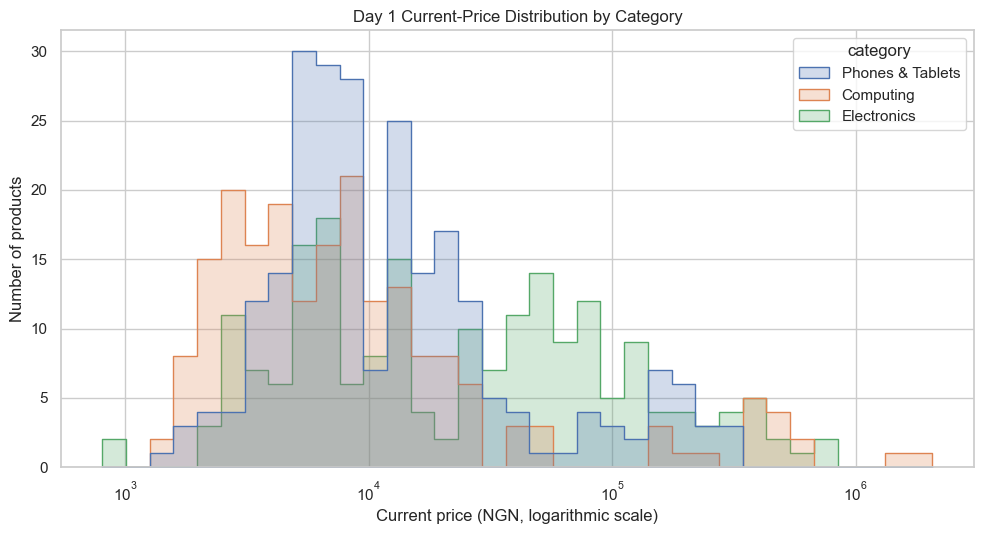

In [7]:
plt.figure(figsize=(10, 5.5))
sns.histplot(
    data=df,
    x="current_price",
    hue="category",
    bins=35,
    element="step",
    stat="count",
    common_norm=False,
    log_scale=(True, False),
)
plt.title("Day 1 Current-Price Distribution by Category")
plt.xlabel("Current price (NGN, logarithmic scale)")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()

The price distributions are strongly right-skewed, so the logarithmic price axis keeps both low-cost accessories and expensive devices visible. Median prices are NGN 6,630 for Computing, NGN 8,999 for Phones & Tablets and NGN 24,786.50 for Electronics, while a small number of high-price products stretch the upper tails. This means the median is more representative than the mean for a typical listed product.

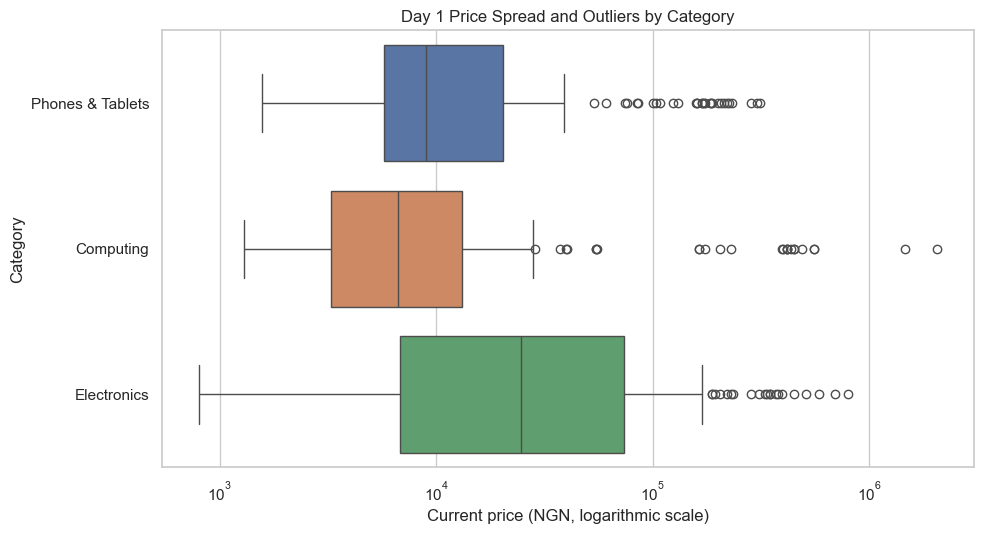

In [8]:
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=df, x="current_price", y="category", hue="category", legend=False)
plt.xscale("log")
plt.title("Day 1 Price Spread and Outliers by Category")
plt.xlabel("Current price (NGN, logarithmic scale)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Using the standard 1.5-IQR rule, Day 1 contains 25 high-price outliers in Computing, 21 in Electronics and 30 in Phones & Tablets. Computing has the largest maximum price at NGN 2,066,198 even though its median is the lowest, showing how strongly expensive computers affect its mean. These are statistical outliers, not automatically data errors, because they remain positive and correspond to real listings.

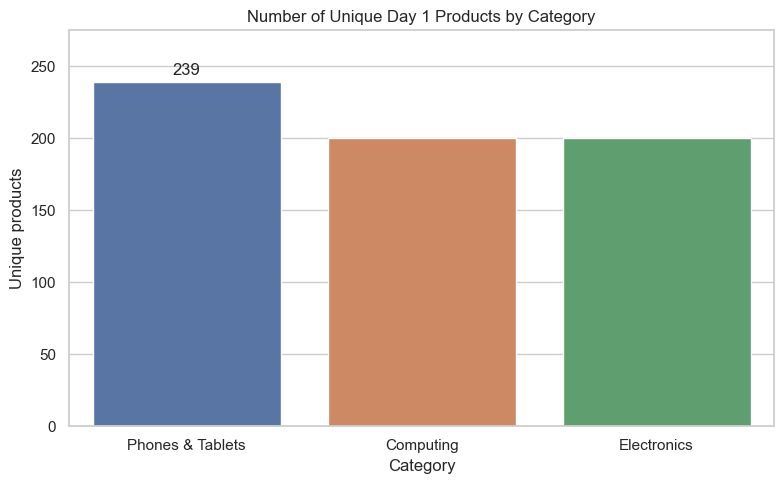

In [9]:
count_frame = category_counts.rename_axis("category").reset_index()
plt.figure(figsize=(8, 5))
axis = sns.barplot(data=count_frame, x="category", y="products", hue="category", legend=False)
axis.bar_label(axis.containers[0], padding=3)
plt.title("Number of Unique Day 1 Products by Category")
plt.xlabel("Category")
plt.ylabel("Unique products")
plt.ylim(0, count_frame["products"].max() * 1.15)
plt.tight_layout()
plt.show()

Phones & Tablets contributes 239 unique products, while Computing and Electronics contribute 200 each. The scraper stopped after reaching its overall target during the sixth Phones & Tablets page, which explains the 39-product difference. All three categories remain strongly represented for preliminary comparison.

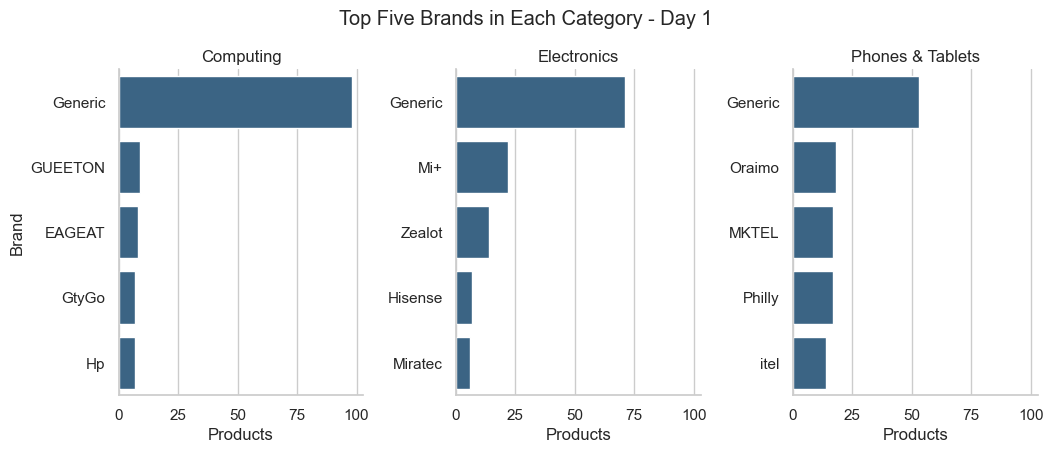

In [10]:
brand_counts = (
    df.groupby(["category", "brand"], dropna=False)
      .size()
      .rename("products")
      .reset_index()
      .sort_values(["category", "products"], ascending=[True, False])
      .groupby("category", group_keys=False)
      .head(5)
)

grid = sns.catplot(
    data=brand_counts,
    x="products",
    y="brand",
    col="category",
    kind="bar",
    sharey=False,
    height=4.3,
    aspect=0.82,
    color="#2F6690",
)
grid.set_axis_labels("Products", "Brand")
grid.set_titles("{col_name}")
grid.figure.suptitle("Top Five Brands in Each Category - Day 1", y=1.05)
plt.show()

The label `Generic` is the most frequent brand in every category: 98 Computing products, 71 Electronics products and 53 Phones & Tablets products. The next visible leaders are GUEETON and EAGEAT in Computing, Mi+ and Zealot in Electronics, and Oraimo and MKTEL in Phones & Tablets. Brand dominance here measures listing frequency in this sample, not sales or market share.

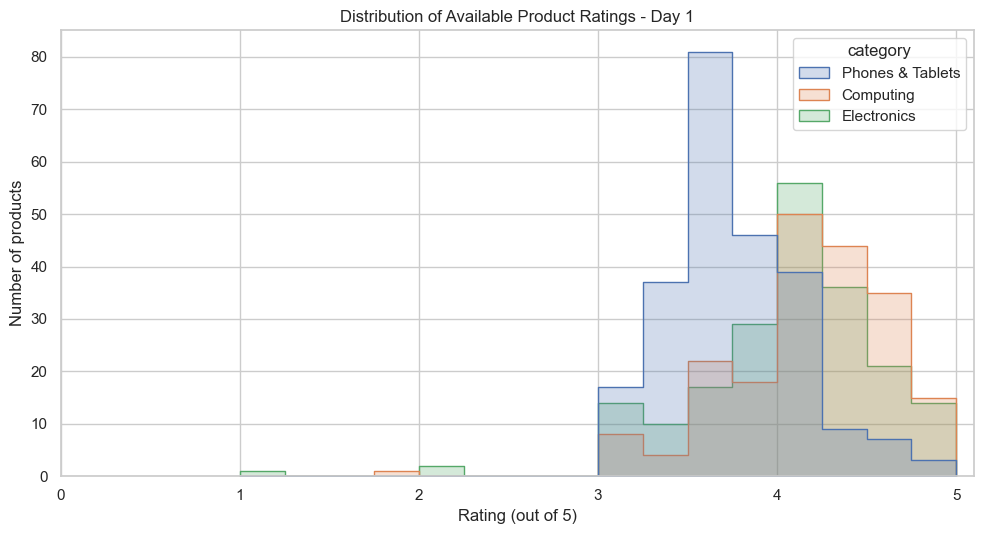

In [11]:
rating_data = df.dropna(subset=["rating"])
plt.figure(figsize=(10, 5.5))
sns.histplot(
    data=rating_data,
    x="rating",
    hue="category",
    binwidth=0.25,
    multiple="layer",
    element="step",
    common_norm=False,
)
plt.title("Distribution of Available Product Ratings - Day 1")
plt.xlabel("Rating (out of 5)")
plt.ylabel("Number of products")
plt.xlim(0, 5.1)
plt.tight_layout()
plt.show()

Ratings are available for 636 of 639 products. Mean ratings are 4.16 for Computing, 4.03 for Electronics and 3.73 for Phones & Tablets, but these are listing-level summaries and do not control for review-count differences. The three missing ratings remain excluded rather than being treated as zero.

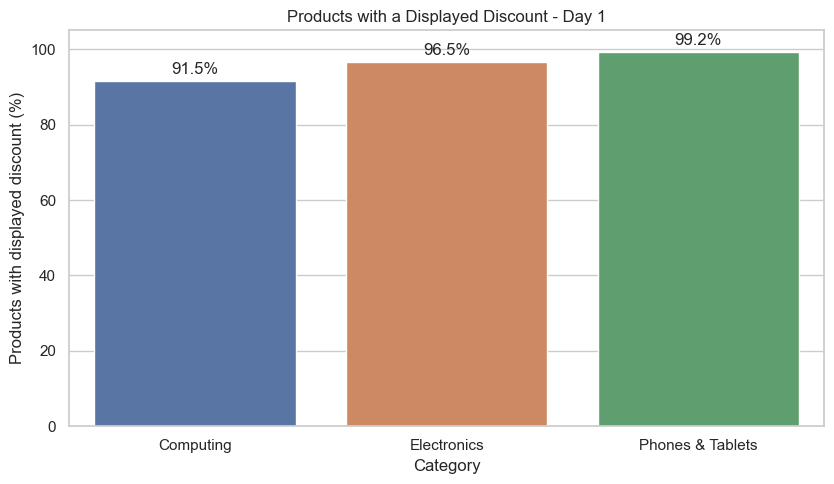

In [12]:
discount_summary = (
    df.groupby("category")
      .agg(
          total_products=("source_product_id", "size"),
          discounted_products=("displayed_discount_percentage", lambda values: values.notna().sum()),
      )
      .reset_index()
)
discount_summary["discounted_percentage"] = (
    discount_summary["discounted_products"] / discount_summary["total_products"] * 100
)

plt.figure(figsize=(8.5, 5))
axis = sns.barplot(
    data=discount_summary,
    x="category",
    y="discounted_percentage",
    hue="category",
    legend=False,
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title("Products with a Displayed Discount - Day 1")
plt.xlabel("Category")
plt.ylabel("Products with displayed discount (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

Displayed discounts are very common in this observation: 99.2% of Phones & Tablets products, 96.5% of Electronics products and 91.5% of Computing products show one. The remaining 26 products are not assumed to have a zero-percent discount; their displayed-discount field is missing because no old-price/discount pair was shown. This chart describes availability of discount evidence, not whether a discount guarantees good value.

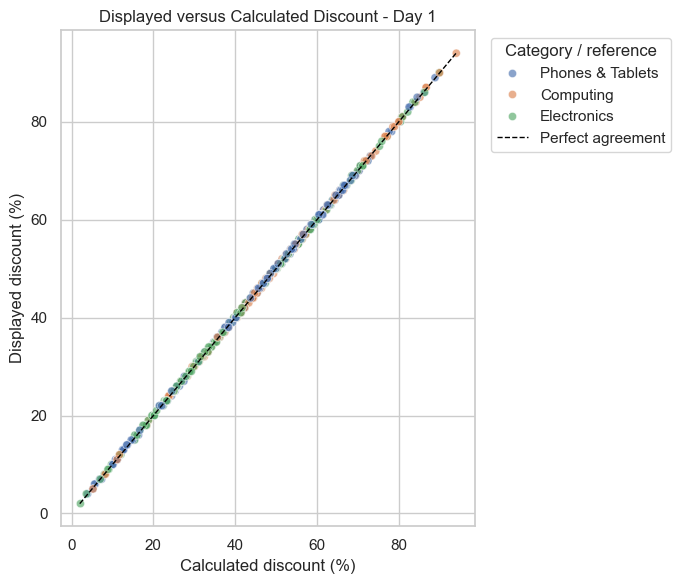

In [13]:
discount_pairs = df.dropna(
    subset=["displayed_discount_percentage", "calculated_discount_percentage"]
).copy()
discount_pairs["absolute_difference"] = (
    discount_pairs["displayed_discount_percentage"]
    - discount_pairs["calculated_discount_percentage"]
).abs()

plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=discount_pairs,
    x="calculated_discount_percentage",
    y="displayed_discount_percentage",
    hue="category",
    alpha=0.65,
    s=35,
)
lower = min(discount_pairs["calculated_discount_percentage"].min(), discount_pairs["displayed_discount_percentage"].min())
upper = max(discount_pairs["calculated_discount_percentage"].max(), discount_pairs["displayed_discount_percentage"].max())
plt.plot([lower, upper], [lower, upper], "--", color="black", linewidth=1, label="Perfect agreement")
plt.title("Displayed versus Calculated Discount - Day 1")
plt.xlabel("Calculated discount (%)")
plt.ylabel("Displayed discount (%)")
plt.legend(title="Category / reference", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

There are 613 products with both displayed and calculated discounts. Their mean absolute difference is 0.243 percentage points and the maximum is 0.55 points; none exceeds the documented two-percentage-point tolerance. The small gaps are consistent with Jumia displaying rounded whole-number percentages while the calculation uses exact listed prices.

## G. Seven-day analysis placeholders

> Only Daily Run 1 is currently available. Seven-day trend conclusions cannot yet be made.

### Daily price changes

Pending genuine Daily Runs 2-7. The final analysis will compare the same stable product IDs across dates and will not fill absent observations with fabricated prices.

### Daily discount changes

Pending genuine Daily Runs 2-7. Displayed and calculated discounts will be compared by product and date.

### Products with the largest movements

Pending at least two genuine observation dates. Movements will be ranked only for products observed on comparable dates.

### Products appearing and disappearing

Pending the multi-day product-ID presence table. Absence from a daily category page will be described as an observed listing absence, not proof that the product left the whole website.

### Final relationship analysis

The final notebook will examine price-rating and review-count relationships after all seven days are combined. Review count will be treated as a limited popularity indicator, not direct sales evidence.

### Original Group 2 research question

**Which brands provide the best balance of lower prices, strong ratings and high review counts?** A scoring method and minimum sample-size rule will be defined after the full period is available; no final brand ranking is claimed from Day 1 alone.

## H. Reproducibility

- Expected cleaned input: `data/cleaned/jumia_ng_products_2026-10-13_cleaned.csv`
- Expected SQLite database: `database/jumia_ng.sqlite` (opened with `mode=ro`)
- Run from the repository root with **Restart Kernel and Run All**, or execute with `jupyter nbconvert --execute --to notebook --inplace notebooks/jumia_analysis.ipynb`.
- Required packages: Python 3, pandas, NumPy, Matplotlib, Seaborn, Jupyter/nbclient and the standard-library `sqlite3` module.
- The notebook reads cleaned data and the database only. The accepted raw CSV must remain unchanged and must be protected by its manifest checksum.
- Re-run the notebook after each accepted daily file is cleaned and loaded; replace placeholders only with results calculated from genuine observations.